<a href="https://colab.research.google.com/github/FatahiraAnggitaS/HS-K-Means_vs_ACO-K-Means/blob/main/HS_K_Means_vs_ACO_K_Means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Library**

In [1]:
!pip install -q openpyxl

import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import pairwise_distances_argmin
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

## **Load Data**

In [17]:
df_data_utama = pd.read_csv ('customer_segmentation.csv')
df_data_utama

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


### **Kategori Per-Fitur**

In [19]:
print(df_data_utama.columns.tolist())

['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


In [20]:
for col in df_data_utama.columns:
    print(f"Kolom: {col}")
    print(df_data_utama[col].unique())
    print("-" * 50)

Kolom: ID
[5524 2174 4141 ... 7270 8235 9405]
--------------------------------------------------
Kolom: Year_Birth
[1957 1954 1965 1984 1981 1967 1971 1985 1974 1950 1983 1976 1959 1952
 1987 1946 1980 1949 1982 1979 1951 1969 1986 1989 1963 1970 1973 1943
 1975 1996 1968 1964 1977 1978 1955 1966 1988 1948 1958 1972 1960 1945
 1991 1962 1953 1961 1956 1992 1900 1893 1990 1947 1899 1993 1994 1941
 1944 1995 1940]
--------------------------------------------------
Kolom: Education
['Graduation' 'PhD' 'Master' 'Basic' '2n Cycle']
--------------------------------------------------
Kolom: Marital_Status
['Single' 'Together' 'Married' 'Divorced' 'Widow' 'Alone' 'Absurd' 'YOLO']
--------------------------------------------------
Kolom: Income
[58138. 46344. 71613. ... 56981. 69245. 52869.]
--------------------------------------------------
Kolom: Kidhome
[0 1 2]
--------------------------------------------------
Kolom: Teenhome
[0 1 2]
--------------------------------------------------
Kolom:

## **Preprocessing Data**

### **Cleaning dan Seleksi Data**

In [21]:
# Tahun lahir > 1920 dianggap outlier
df_clean = df_data_utama[df_data_utama['Year_Birth'] >= 1920].copy()

# Kategori baru pada Marital_Status
status_mapping = {
    'Absurd': 'Single',
    'YOLO': 'Single',
    'Alone': 'Single'
}
df_clean['Marital_Status'] = df_clean['Marital_Status'].replace(status_mapping)

# Ubah format kolom tanggal dari string ke datetime
df_clean['Dt_Customer'] = pd.to_datetime(df_clean['Dt_Customer'], format='%d-%m-%Y')

# Hapus NaN pada fitur income
df_clean = df_clean.dropna(subset=['Income']).copy()

print("Dimensi data setelah cleaning:", df_clean.shape)

Dimensi data setelah cleaning: (2213, 29)


In [24]:
referensi_tanggal = df_clean['Dt_Customer'].max()

# Membuat fitur-fitur baru hasil rangkuman kolom mentah
df_clean['Age'] = referensi_tanggal.year - df_clean['Year_Birth']
df_clean['Tenure_Days'] = (referensi_tanggal - df_clean['Dt_Customer']).dt.days
df_clean['Total_Spend'] = (df_clean['MntWines'] + df_clean['MntFruits'] +
                           df_clean['MntMeatProducts'] + df_clean['MntFishProducts'] +
                           df_clean['MntSweetProducts'] + df_clean['MntGoldProds'])
df_clean['Total_Purchases'] = (df_clean['NumWebPurchases'] +
                               df_clean['NumCatalogPurchases'] +
                               df_clean['NumStorePurchases'])
df_clean['Total_Children'] = df_clean['Kidhome'] + df_clean['Teenhome']

# 6 fitur terpilih untuk proses algoritma
fitur_kmeans = ['Age', 'Tenure_Days', 'Income', 'Total_Spend', 'Total_Purchases', 'Total_Children']
df_final = df_clean[fitur_kmeans].copy()
df_final.head()

,Age,Tenure_Days,Income,Total_Spend,Total_Purchases,Total_Children
0,57,663,58138.0,1617,22,0
1,60,113,46344.0,27,4,2
2,49,312,71613.0,776,20,0
3,30,139,26646.0,53,6,1
4,33,161,58293.0,422,14,1


In [47]:
from sklearn.preprocessing import StandardScaler

scaler_zscore = StandardScaler()
df_normalized = pd.DataFrame(
    scaler_zscore.fit_transform(df_final),
    columns=df_final.columns,
    index=df_final.index
)

df_normalized.head()

,Age,Tenure_Days,Income,Total_Spend,Total_Purchases,Total_Children
0,1.018785,1.527968,0.234435,1.676723,1.309929,-1.264914
1,1.275248,-1.189356,-0.234084,-0.962927,-1.188980,1.404857
2,0.334882,-0.206179,0.769733,0.280531,1.032273,-1.264914
3,-1.289387,-1.060901,-1.016592,-0.919763,-0.911323,0.069971
4,-1.032923,-0.952208,0.240593,-0.307165,0.199303,0.069971


## **Proses Klasterisasi**

### **Klasterisasi Harmony Search**

In [117]:
def assign_cluster(X, centroids):
    return pairwise_distances_argmin(X, centroids)

def calculate_sse(X, centroids, labels):
    sse = 0
    for i in range(len(centroids)):
        cluster_points = X[labels == i]
        if len(cluster_points) > 0:
            sse += np.sum((cluster_points - centroids[i]) ** 2)
    return sse

def fitness_function(X, centroids):
    labels = assign_cluster(X, centroids)
    if len(np.unique(labels)) < len(centroids):
        return np.inf
    return calculate_sse(X, centroids, labels)

In [118]:
# Inisialisasi parameter
def harmony_search(X, k, HMS=5, HMCR=0.95, PAR=0.3, BW=1, max_iter=700, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    n_samples, n_features = X.shape

    LB = np.min(X, axis=0)
    UB = np.max(X, axis=0)

    def generate_random_centroids():
        centroids = np.zeros((k, n_features))
        for i in range(k):
            for j in range(n_features):
                centroids[i, j] = LB[j] + np.random.rand() * (UB[j] - LB[j])
        return centroids

    # Memulai inisialisasai harmony memory
    HM = []
    HM_fitness = []

    for _ in range(HMS):
        centroid = generate_random_centroids()
        fitness = fitness_function(X, centroid)

        HM.append(centroid)
        HM_fitness.append(fitness)

    HM = np.array(HM)
    HM_fitness = np.array(HM_fitness)

    # Sebagai penyimpanan histori SSE
    best_sse_history = []

    # Iterasi Harmony Search
    for _ in range(max_iter):
        new_harmony = np.zeros((k, n_features))
        for i in range(k):
            for j in range(n_features):

                # Mengambil acak dari HM
                r1 = np.random.rand()
                if r1 < HMCR:
                    harmony_index = np.random.randint(HMS)
                    new_harmony[i, j] = HM[harmony_index, i, j]

                # Pitch Adjustment
                    r2 = np.random.rand()
                    if r2 < PAR:
                        new_harmony[i, j] += np.random.rand() * BW

                # # Mengambil acak dari rentang LB dan UB
                else:
                    new_harmony[i, j] = LB[j] + np.random.rand() * (UB[j] - LB[j])

        # Evaluasi fitness solusi baru
        new_fitness = fitness_function(X, new_harmony)
        worst = np.argmax(HM_fitness)

        # Perbarui HM jika SSE lebih kecil
        if new_fitness < HM_fitness[worst]:
            HM[worst] = new_harmony
            HM_fitness[worst] = new_fitness

        # Simpan SSE terbaik
        best_sse_history.append(np.min(HM_fitness))

    best = np.argmin(HM_fitness)
    best_centroid = HM[best]
    labels = assign_cluster(X, best_centroid)
    sse = calculate_sse(X, best_centroid, labels)
    sc = silhouette_score(X, labels)

    return sse, sc, best_sse_history, best_centroid

### **Klasterisasi Ant Colony Optimization**

In [120]:
def ant_colony(X, k, n_ants=5, evaporation=0.5, alpha=1, q=1, Max_Iter=700, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)

    n_samples, n_features = X.shape

    LB = np.min(X, axis=0)
    UB = np.max(X, axis=0)

    # Inisialisasi koloni semut (solusi centroid) dan fitness (SSE)
    ants = []
    fitness = []

    for _ in range(n_ants):
        centroid_solution = np.zeros((k, n_features))
        for i in range(k):
            # Inisialisasi setiap centroid secara acak dalam rentang data
            for j in range(n_features):
                centroid_solution[i, j] = LB[j] + np.random.rand() * (UB[j] - LB[j])
        ants.append(centroid_solution)
        fitness.append(fitness_function(X, centroid_solution))

    ants = np.array(ants)
    fitness = np.array(fitness)
    pheromone = np.ones(n_ants)

    best_sse_history = []

    # Iterasi Algoritma Ant Colony Optimization
    for _ in range(Max_Iter):
        # Pembaruan Feromon (Evaporasi)
        pheromone = (1 - evaporation) * pheromone

        # Pembaruan Feromon (Deposisi)
        for i in range(n_ants):
            pheromone[i] += q / (1 + fitness[i])

        # Probabilitas Seleksi
        probability = pheromone**alpha
        probability /= probability.sum()

        new_ants_solutions = []
        new_fitness_values = []

        # Pembentukan Semut Baru
        for i in range(n_ants):
            guide_index = np.random.choice(n_ants, p=probability)
            new_centroid_candidate = ants[guide_index].copy()
            noise = np.random.uniform(low=-0.1, high=0.1, size=(k, n_features)) * (UB - LB)

            new_centroid_candidate = new_centroid_candidate + noise
            new_centroid_candidate = np.clip(new_centroid_candidate, LB, UB)

            fit_new = fitness_function(X, new_centroid_candidate)

            new_ants_solutions.append(new_centroid_candidate)
            new_fitness_values.append(fit_new)

        new_ants_solutions = np.array(new_ants_solutions)
        new_fitness_values = np.array(new_fitness_values)

        # Seleksi Solusi Terbaik
        for i in range(n_ants):
            if new_fitness_values[i] < fitness[i]:
                ants[i] = new_ants_solutions[i]
                fitness[i] = new_fitness_values[i]

        # Menyimpan SSE terbaik dari koloni pada iterasi saat ini
        best_sse_history.append(np.min(fitness))

    best_solution_index = np.argmin(fitness)
    final_best_centroid = ants[best_solution_index]
    final_labels = assign_cluster(X, final_best_centroid)
    final_sse = calculate_sse(X, final_best_centroid, final_labels)
    final_sc = silhouette_score(X, final_labels)

    return final_sse, final_sc, best_sse_history, final_best_centroid

### **Pengujian 30 Percobaan**

In [121]:
X = df_normalized.values.astype(float)
n_runs = 30
records = []

# Memperbaiki range agar dimulai dari k=2 (bukan k=0)
for k in range(2, 6):
    print(f"\nMemproses jumlah k={k} . . .")
    for run in range(n_runs):
        seed = run * 7

        # K-Means Biasa
        km = KMeans(n_clusters=k, init='random', n_init=1, random_state=seed)
        labels = km.fit_predict(X)
        sse_km = km.inertia_
        sc_km = silhouette_score(X, labels)

        # Harmony Search
        sse_hs, sc_hs, _, best_centroids_hs = harmony_search(X, k=k, random_state=seed)

        # Ant Colony
        sse_aco, sc_aco, _, best_centroids_aco = ant_colony(X, k=k, random_state=seed)

        records.append({
            "Cluster": k,
            "Run": run + 1,

            "SSE_KMeans": round(sse_km,2),
            "SC_KMeans": round(sc_km,4),

            "SSE_HS": round(sse_hs,2),
            "SC_HS": round(sc_hs,4),

            "SSE_ACO":round(sse_aco,2),
            "SC_ACO":round(sc_aco,4),

            "Best_Centroids_HS":best_centroids_hs,
            "Best_Centroids_ACO":best_centroids_aco
        })


Memproses jumlah k=2 . . .

Memproses jumlah k=3 . . .

Memproses jumlah k=4 . . .

Memproses jumlah k=5 . . .


### **Rekapitulasi Nilai SSE dan SC**

In [122]:
df_result = pd.DataFrame(records)
display(df_result)

,Cluster,Run,SSE_KMeans,SC_KMeans,SSE_HS,SC_HS,SSE_ACO,SC_ACO,Best_Centroids_HS,Best_Centroids_ACO
0,2,1,8534.55,0.3315,12925.51,0.8697,12724.84,0.8697,"[[-0.13263632218569477, 0.1711379783290875, 0....","[[-0.039319275712140306, -0.05375226584386945,..."
1,2,2,8534.56,0.3314,13464.06,0.8697,9049.31,0.3314,"[[2.0992054042040973, 1.9047872098969814, 24.5...","[[0.06736898595538443, 0.5470257752790118, 0.7..."
2,2,3,8534.55,0.3315,12820.78,0.8697,9066.78,0.3268,"[[2.0722152895406474, 0.8636453003276261, 20.3...","[[-0.011323503416814026, -0.30812826862010245,..."
3,2,4,12922.77,0.6543,13025.63,0.8697,12867.21,0.8697,"[[0.0697164239320317, 0.25826904641949744, 0.1...","[[1.8993614565788168, 1.705829484181711, 20.33..."
4,2,5,8534.56,0.3314,13902.91,0.8697,12808.52,0.8697,"[[0.28886981055986594, 0.3898502305007021, -0....","[[-0.0023676333995149013, -0.1730804858086321,..."
...,...,...,...,...,...,...,...,...,...,...
115,5,26,6113.74,0.2009,10100.77,0.1906,7526.02,0.2174,"[[2.90212399762679, 0.8519049882996779, 1.6296...","[[-2.2417336235370637, -0.29735164351018817, 2..."
116,5,27,6058.46,0.2205,9663.26,0.3257,8117.35,0.2019,"[[2.38323070869337, 1.1834996763048196, 5.4601...","[[-0.5396661288912235, 0.9799532940668119, 0.4..."
117,5,28,6115.18,0.2009,8440.41,0.2352,31883.67,0.4178,"[[-0.006714785806696377, -0.11935594283423046,...","[[-0.2915969129221381, -0.4425806557155967, 20..."
118,5,29,6085.84,0.2038,9020.81,0.2928,17020.88,0.8697,"[[-0.17630890734050464, -0.0004099737968781269...","[[0.9856597543304897, 0.24837930141045295, -0...."


Rata-rata nilai evaluasi semua metode

In [133]:
summary = (
df_result
    .groupby("Cluster")
    .agg({
        "SC_KMeans":"mean",
        "SC_HS":"mean",
        "SC_ACO":"mean",
        "SSE_KMeans":"mean",
        "SSE_HS":"mean",
        "SSE_ACO":"mean"
    })
    .round(4)
)

display(summary)

,SC_KMeans,SC_HS,SC_ACO,SSE_KMeans,SSE_HS,SSE_ACO
Cluster,,,,,,
2,0.3422,0.8335,0.7436,8680.8400,13050.2610,11982.0533
3,0.2469,0.3123,0.3179,7573.1260,10982.1207,8923.5773
4,0.2159,0.2697,0.2674,6726.4057,12726.2320,8952.9463
5,0.2148,0.2649,0.3068,6086.3907,24972.7117,50473.4807


### **Klasterisasi Hybrid**

Klasterisasi hybrid HS + K-Means

In [134]:
hybrid_hs_results_list = []
k_optimal_fixed = 2

df_cluster_k = df_result[df_result['Cluster'] == k_optimal_fixed]

for index, row in df_cluster_k.iterrows():
    run_num = row['Run']
    hs_centroids = row['Best_Centroids_HS']

    kmeans_hybrid = KMeans(n_clusters=k_optimal_fixed, init=hs_centroids, n_init=1, random_state=None)
    labels_hybrid = kmeans_hybrid.fit_predict(X)
    sse_hybrid = kmeans_hybrid.inertia_
    sc_hybrid = silhouette_score(X, labels_hybrid)

    hybrid_hs_results_list.append({
        "Cluster": k_optimal_fixed,
        "Run": run_num,
        "SSE HS+KMeans": round(sse_hybrid, 2),
        "SC HS+KMeans": round(sc_hybrid, 4),
        "Centroids_HS_KMeans_Hybrid": kmeans_hybrid.cluster_centers_,
    })

df_hybrid_hs_results = pd.DataFrame(hybrid_hs_results_list)
display(df_hybrid_hs_results.drop(columns=['Centroids_HS_KMeans_Hybrid']))

,Cluster,Run,SSE HS+KMeans,SC HS+KMeans
0,2,1,12680.03,0.8697
1,2,2,12680.03,0.8697
2,2,3,12680.03,0.8697
3,2,4,12680.03,0.8697
4,2,5,12680.03,0.8697
5,2,6,12680.03,0.8697
6,2,7,12680.03,0.8697
7,2,8,12680.03,0.8697
8,2,9,8534.55,0.3315
9,2,10,12680.03,0.8697


Rata-rata nilai evaluasi setelah klasterisasi hybrid HS + K-Means

In [135]:
summary_hs_kmeans = (
df_hybrid_hs_results
    .groupby("Cluster")
    .agg({
        "SSE HS+KMeans":"mean",
        "SC HS+KMeans":"mean"
    })
    .round(4)
)

display(summary_hs_kmeans)

,SSE HS+KMeans,SC HS+KMeans
Cluster,,
2,12403.6647,0.8338


Klasterisasi hybrid ACO + K-Means

In [136]:
hybrid_aco_results_list = []
k_optimal_aco = 2

df_cluster_2 = df_result[df_result['Cluster'] == k_optimal_aco]

for index, row in df_cluster_2.iterrows():
    run_num = row['Run']
    aco_centroids = row['Best_Centroids_ACO']

    kmeans_hybrid = KMeans(n_clusters=k_optimal_aco, init=aco_centroids, n_init=1, random_state=None)
    labels_hybrid = kmeans_hybrid.fit_predict(X)
    sse_hybrid = kmeans_hybrid.inertia_
    sc_hybrid = silhouette_score(X, labels_hybrid)

    hybrid_aco_results_list.append({
        "Cluster": k_optimal_aco,
        "Run": run_num,
        "SSE ACO+KMeans": round(sse_hybrid, 2),
        "SC ACO+KMeans": round(sc_hybrid, 4),
        "Centroids_ACO_KMeans_Hybrid": kmeans_hybrid.cluster_centers_,
    })

df_hybrid_aco_results = pd.DataFrame(hybrid_aco_results_list)
display(df_hybrid_aco_results.drop(columns=['Centroids_ACO_KMeans_Hybrid']))

,Cluster,Run,SSE ACO+KMeans,SC ACO+KMeans
0,2,1,12680.03,0.8697
1,2,2,8534.55,0.3315
2,2,3,8534.55,0.3315
3,2,4,12680.03,0.8697
4,2,5,12680.03,0.8697
5,2,6,12680.03,0.8697
6,2,7,12680.03,0.8697
7,2,8,12680.03,0.8697
8,2,9,12680.03,0.8697
9,2,10,12680.03,0.8697


Rata-rata nilai evaluasi setelah klasterisasi hybrid ACO + K-Means

In [137]:
summary_aco_kmeans = (
df_hybrid_aco_results
    .groupby("Cluster")
    .agg({
        "SSE ACO+KMeans":"mean",
        "SC ACO+KMeans":"mean"
    })
    .round(4)
)

display(summary_aco_kmeans)

,SSE ACO+KMeans,SC ACO+KMeans
Cluster,,
2,11712.753,0.7441


## **Visualisasi Hasil Klasterisasi**

### **Rata-Rata Evaluasi SSE**

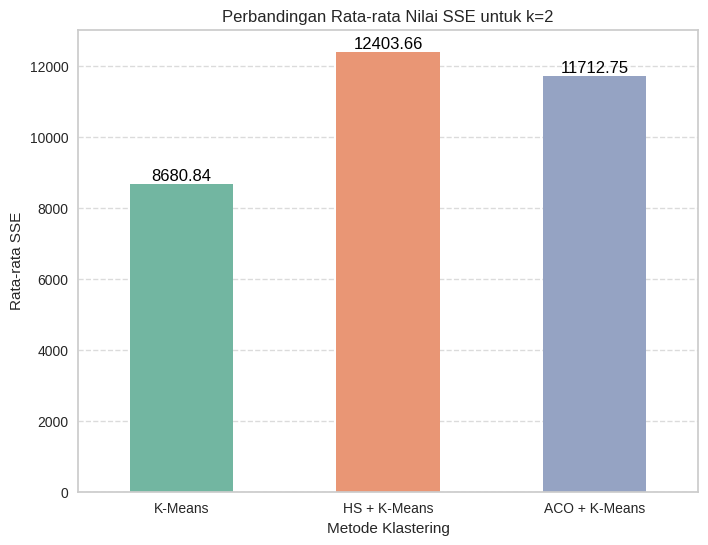

In [138]:
sse_kmeans_avg = summary.loc[k_optimal_fixed, 'SSE_KMeans']
sse_hs_kmeans_avg = summary_hs_kmeans.loc[k_optimal_fixed, 'SSE HS+KMeans']
sse_aco_kmeans_avg = summary_aco_kmeans.loc[k_optimal_aco, 'SSE ACO+KMeans']

methods = ['K-Means', 'HS + K-Means', 'ACO + K-Means']
sse_values = [sse_kmeans_avg, sse_hs_kmeans_avg, sse_aco_kmeans_avg]

df_sse_comparison = pd.DataFrame({
    'Method': methods,
    'Average SSE': sse_values
})

plt.figure(figsize=(8, 6))
ax = sns.barplot(x='Method', y='Average SSE', data=df_sse_comparison, palette='Set2', width=0.5, hue='Method', legend=False)
plt.title(f'Perbandingan Rata-rata Nilai SSE untuk k={k_optimal_fixed}')
plt.xlabel('Metode Klastering')
plt.ylabel('Rata-rata SSE')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for index, row in df_sse_comparison.iterrows():
    ax.text(index, row['Average SSE'] + (row['Average SSE'] * 0.001), f"{row['Average SSE']:.2f}", color='black', ha="center", va="bottom")

plt.show()

### **Rata-Rata Evaluasi SC**

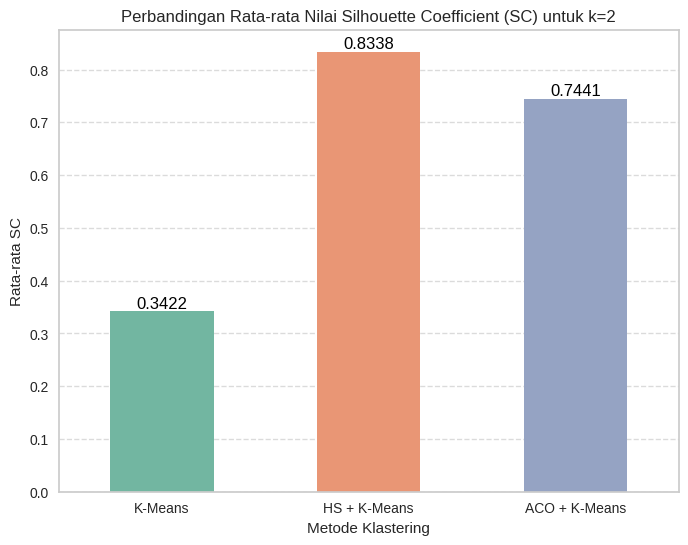

In [139]:
sc_kmeans_avg = summary.loc[k_optimal_fixed, 'SC_KMeans']
sc_hs_kmeans_avg = summary_hs_kmeans.loc[k_optimal_fixed, 'SC HS+KMeans']
sc_aco_kmeans_avg = summary_aco_kmeans.loc[k_optimal_aco, 'SC ACO+KMeans']

methods = ['K-Means', 'HS + K-Means', 'ACO + K-Means']
sc_values = [sc_kmeans_avg, sc_hs_kmeans_avg, sc_aco_kmeans_avg]

df_sc_comparison = pd.DataFrame({
    'Method': methods,
    'Average SC': sc_values
})

plt.figure(figsize=(8, 6))
ax = sns.barplot(x='Method', y='Average SC', data=df_sc_comparison, palette='Set2', width=0.5, hue='Method', legend=False)
plt.title(f'Perbandingan Rata-rata Nilai Silhouette Coefficient (SC) untuk k={k_optimal_fixed}')
plt.xlabel('Metode Klastering')
plt.ylabel('Rata-rata SC')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for index, row in df_sc_comparison.iterrows():
    ax.text(index, row['Average SC'] + (row['Average SC'] * 0.001), f"{row['Average SC']:.4f}", color='black', ha="center", va="bottom")

plt.show()

## **Uji P-Value**

### **Uji SSE**

In [151]:
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations

df_result_k_optimal = df_result[df_result['Cluster'] == k_optimal_fixed].copy()
df_uji = df_result_k_optimal[['Run', 'SSE_KMeans', 'SC_KMeans']].copy()
df_uji = df_uji.merge(df_hybrid_hs_results[['Run', 'SSE HS+KMeans', 'SC HS+KMeans']], on='Run', how='left')
df_uji = df_uji.merge(df_hybrid_aco_results[['Run', 'SSE ACO+KMeans', 'SC ACO+KMeans']], on='Run', how='left')

print("-"*50)
print(f"UJI FRIEDMAN UNTUK SSE (k = {k_optimal_fixed})")
print("-"*50)

sse_kmeans = df_uji["SSE_KMeans"].values
sse_hs = df_uji["SSE HS+KMeans"].values
sse_aco = df_uji["SSE ACO+KMeans"].values
stat_sse, p_sse = friedmanchisquare(sse_kmeans, sse_hs, sse_aco)

ket_friedman = "(Signifikan)" if p_sse < 0.05 else "(Tidak Signifikan)"
print(f"Statistic : {stat_sse:.4f}")
print(f"P-value   : {p_sse:.6f} {ket_friedman}")

if p_sse < 0.05:
    print("\nKeputusan : Ada perbedaan yang signifikan.\n")
    methods = {"K-Means": sse_kmeans, "HS+KMeans": sse_hs, "ACO+KMeans": sse_aco}
    print("Post-hoc Wilcoxon:")
    for m1, m2 in combinations(methods.keys(), 2):
        stat, p = wilcoxon(methods[m1], methods[m2])
        ket_wilcoxon = "(Signifikan)" if p < 0.05 else "(Tidak Signifikan)"
        print(f"{m1:12s} vs {m2:12s} -> p = {p:.6f} {ket_wilcoxon}")
else:
    print("\nKeputusan : Tidak ada perbedaan yang signifikan.")

--------------------------------------------------
UJI FRIEDMAN UNTUK SSE (k = 2)
--------------------------------------------------
Statistic : 30.0625
P-value   : 0.000000 (Signifikan)

Keputusan : Ada perbedaan yang signifikan.

Post-hoc Wilcoxon:
K-Means      vs HS+KMeans    -> p = 0.000003 (Signifikan)
K-Means      vs ACO+KMeans   -> p = 0.000023 (Signifikan)
HS+KMeans    vs ACO+KMeans   -> p = 0.114404 (Tidak Signifikan)


### **Uji SC**

In [150]:
print("-"*50)
print(f"UJI FRIEDMAN UNTUK SILHOUETTE COEFFICIENT (k = {k_optimal_fixed})")
print("-"*50)

sc_kmeans = df_uji["SC_KMeans"].values
sc_hs = df_uji["SC HS+KMeans"].values
sc_aco = df_uji["SC ACO+KMeans"].values
stat_sc, p_sc = friedmanchisquare(sc_kmeans, sc_hs, sc_aco)

ket_friedman_sc = "(Signifikan)" if p_sc < 0.05 else "(Tidak Signifikan)"
print(f"Statistic : {stat_sc:.4f}")
print(f"P-value   : {p_sc:.6f} {ket_friedman_sc}")

if p_sc < 0.05:
    print("\nKeputusan : Ada perbedaan yang signifikan.\n")
    methods = {"K-Means": sc_kmeans, "HS+KMeans": sc_hs, "ACO+KMeans": sc_aco}
    print("Post-hoc Wilcoxon:")
    for m1, m2 in combinations(methods.keys(), 2):
        stat, p = wilcoxon(methods[m1], methods[m2])
        ket_wilcoxon_sc = "(Signifikan)" if p < 0.05 else "(Tidak Signifikan)"
        print(f"{m1:9s} vs {m2:12s} -> p = {p:.6f} {ket_wilcoxon_sc}")
else:
    print("\nKeputusan : Tidak ada perbedaan yang signifikan.")

--------------------------------------------------
UJI FRIEDMAN UNTUK SILHOUETTE COEFFICIENT (k = 2)
--------------------------------------------------
Statistic : 51.6458
P-value   : 0.000000 (Signifikan)

Keputusan : Ada perbedaan yang signifikan.

Post-hoc Wilcoxon:
K-Means   vs HS+KMeans    -> p = 0.000001 (Signifikan)
K-Means   vs ACO+KMeans   -> p = 0.000003 (Signifikan)
HS+KMeans vs ACO+KMeans   -> p = 0.057780 (Tidak Signifikan)


## **Kesimpulan**

Berdasarkan hasil pengujian pada jumlah klaster \(k=2\), metode K-Means menghasilkan rata-rata SSE sebesar 8.680,84 dan Silhouette Coefficient sebesar 0,3422. Metode HS + K-Means menghasilkan rata-rata SSE sebesar 12.403,66 dan Silhouette Coefficient sebesar 0,8338, sedangkan ACO + K-Means menghasilkan rata-rata SSE sebesar 11.712,75 dan Silhouette Coefficient sebesar 0,7441.

Hasil tersebut menunjukkan bahwa HS + K-Means menghasilkan rata-rata Silhouette Coefficient tertinggi di antara ketiga metode, sehingga memberikan kualitas pemisahan klaster yang lebih baik berdasarkan metrik tersebut. Namun, HS + K-Means tidak menghasilkan SSE terendah. Berdasarkan uji Friedman, terdapat perbedaan yang signifikan di antara ketiga metode pada metrik SSE dan Silhouette Coefficient. Selanjutnya, uji Wilcoxon menunjukkan perbedaan signifikan antara K-Means dan HS + K-Means pada kedua metrik, sedangkan perbedaan antara HS + K-Means dan ACO + K-Means tidak signifikan pada taraf signifikansi 5%.

Dengan demikian, penerapan Harmony Search pada K-Means menunjukkan hasil yang menjanjikan dalam meningkatkan kualitas pemisahan klaster berdasarkan Silhouette Coefficient dibandingkan K-Means biasa. Akan tetapi, keunggulan Harmony Search dibandingkan ACO + K-Means belum dapat dibuktikan secara statistik berdasarkan hasil pengujian yang dilakukan.